### Deep Velo Figure 2 Follow
#### By: Josh Navaro

Link to the tutorial: https://github.com/bowang-lab/DeepVelo/blob/main/examples/figure2.ipynb

Link to the article: https://link.springer.com/article/10.1186/s13059-023-03148-9

In [1]:
# Imports that we will be using
import numpy as np
import scvelo as scv
import torch
from umap import UMAP
from sklearn.decomposition import PCA
from scipy.stats import mannwhitneyu
import anndata as ann
import scanpy as sc

from deepvelo.utils import (
    velocity,
    velocity_confidence,
    continuity_confidence,
    update_dict,
    cross_boundary_correctness,
)
from deepvelo.utils.scatter import scatter
from deepvelo.utils.preprocess import autoset_coeff_s
from deepvelo.utils.plot import statplot, compare_plot
from deepvelo import train, Constants

Using backend: pytorch
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\deepvelo\utils\scatter.py:5: DeprecationWarning: deepvelo.utils.scatter is deprecated. Please use deepvelo.plot.scatter instead.
  warnings.warn(
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\deepvelo\utils\plot.py:5: DeprecationWarning: deepvelo.utils.plot is deprecated. Please use deepvelo.plot.plot instead.
  warnings.warn(


In [2]:
# use this fixed seed for the reproducibility
SEED = 123
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
np.random.seed(SEED)

scv.settings.verbosity = 3  # show errors(0), warnings(1), info(2), hints(3)
scv.settings.set_figure_params(
    "scvelo", transparent=False
)

## Load the DG data and preprocess

I think this is the wrong the data, compared to the data that is used in the article, but I think it is fine.

In [4]:
# Load in the data.
# adata = scv.datasets.dentategyrus() doesnt work since I am on the school wifi
adata = ann.read_h5ad(r"C:\Users\joshu\Desktop\RNA_Velocity_R\DeepVelo\Figure_2_Follow\human_cd34_bone_marrow.h5ad")
print(f"expression value stats, mean {adata.X.mean()}, max {adata.X.max()}")
print(f"spliced value stats, mean {adata.layers['spliced'].mean()}, max {adata.layers['spliced'].max()}")

scv.pp.filter_and_normalize(adata, min_shared_counts=20, n_top_genes=2000)
scv.pp.moments(adata, n_neighbors=30, n_pcs=30)
print(f"processed expression, mean {adata.X.mean()}, max {adata.X.max()}")
print(f"processed spliced stats, mean {adata.layers['spliced'].mean()}, max {adata.layers['spliced'].max()}")
print(f"Ms stats, mean {adata.layers['Ms'].mean()}, max {adata.layers['Ms'].max()}")

expression value stats, mean 0.15655075013637543, max 1127.0
spliced value stats, mean 0.15655074886586814, max 1127
Filtered out 7837 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.
Extracted 2000 highly variable genes.
Logarithmized X.
computing neighbors
    finished (0:00:03) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
processed expression, mean 0.1096733957529068, max 5.782790660858154
processed spliced stats, mean 0.23153525590896606, max 323.6639099121094
Ms stats, mean 0.22838951647281647, max 148.19532775878906


## DeepVelo

Customize the configuration to fit the needs for the experiment. 

In [5]:
# The specific configs to overide the default configs
configs = {
    "name": "DeepVelo", # name of the experiment
    "loss": {"args": {"coeff_s": autoset_coeff_s(adata)}},
    "trainer": {"verbosity": 0}, # increase verbosity to show training progress
}
configs = update_dict(Constants.default_configs, configs)

The ratio of spliced reads is 52.1% (less than 70%). Suggest using coeff_s 0.5.


Train the model on the data provided. 

In [6]:
# The initial velocity

velocity(adata, mask_zero=False)
trainer = train(adata, configs)


computing velocities
    finished (0:00:01) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
Config Warning: Set to use GPU, but GPU version of DGL is not installed. Reset to use CPU instead.
building graph


INFO:train:Beginning training of DeepVelo ...


velo data shape: torch.Size([5780, 2000])
confidence mse shape: (5780, 2000)
confidence mse stats: max 1575.8189697265625, min 0.0, mean 0.23968741297721863, std 2.4566919803619385
confidence corr shape: (2000,)
confidence corr stats: max 0.871008574962616, min -0.13662399351596832, mean 0.57894366979599, std 0.12608826160430908
velo_mat shape: (5780, 2000)
--> added 'velocity' (adata.layers)
--> added 'velocity_unspliced' (adata.layers)
--> added 'cell_specific_beta' (adata.layers)
--> added 'cell_specific_gamma' (adata.layers)


Created the UMAP since the data didnt have this. 

In [ ]:
# Create a umap
sc.pp.neighbors(  
    adata,
    n_neighbors=30, # Find the nearby cells
    n_pcs=30 # Search the first principal components
)

sc.tl.umap(adata)

In [8]:
# Confirm the umap was created
print("X_umap" in adata.obsm)
print(adata.obsm["X_umap"].shape)

True
(5780, 2)


In [9]:
# Compute the velocity graph
scv.tl.velocity_graph(adata, n_jobs = 4)

computing velocity graph (using 4/8 cores)


  0%|          | 0/5780 [00:00<?, ?cells/s]

    finished (0:00:08) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


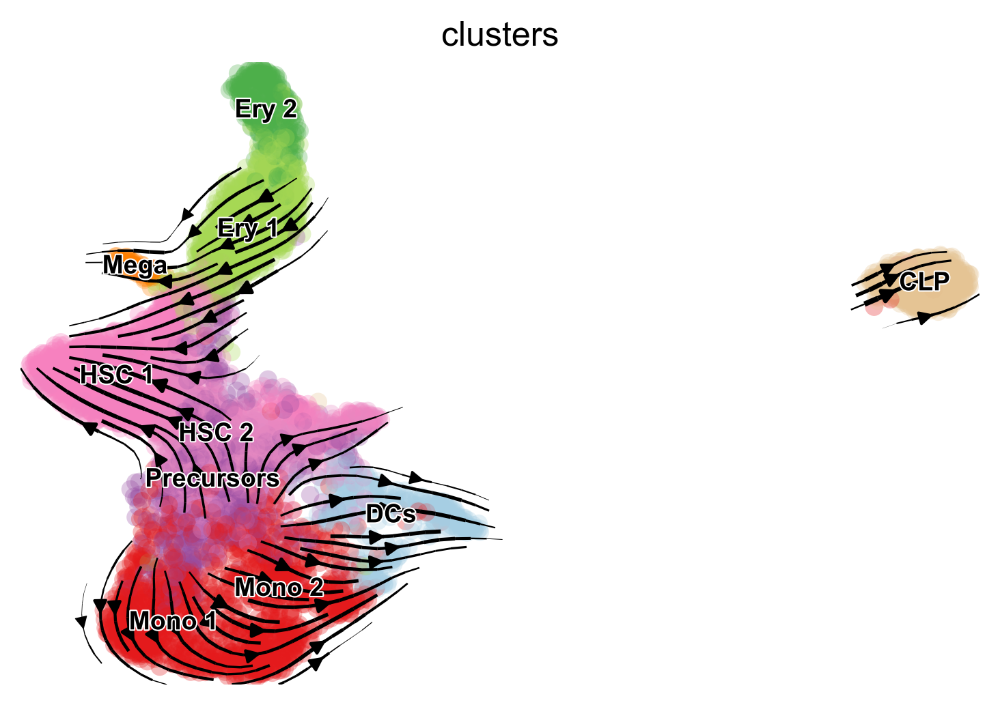

In [10]:
# Create a velocity plot
scv.pl.velocity_embedding_stream(
    adata,
    basis="umap",
    color="clusters",
    legend_fontsize=9,
    dpi=150            # increase dpi for higher resolution
)

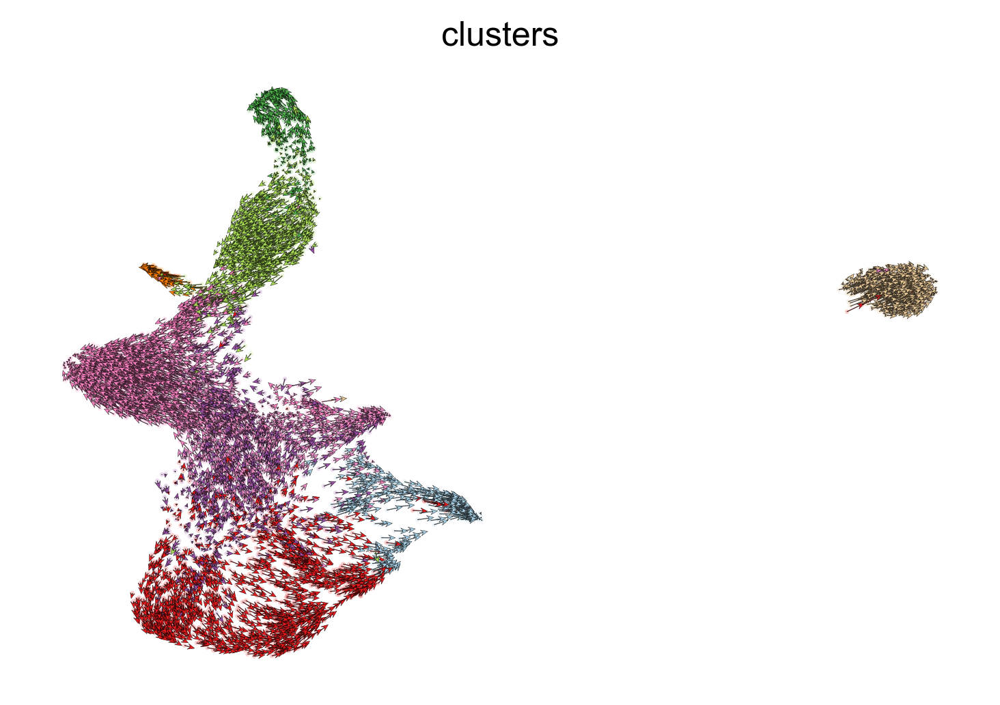

In [11]:
# Create another velocity plot
scv.pl.velocity_embedding(
    adata,
    basis="umap",
    arrow_length=6, # Change the arrow length
    arrow_size=1.2, # Change the arrow size
    dpi=150, # Change the resolution
)

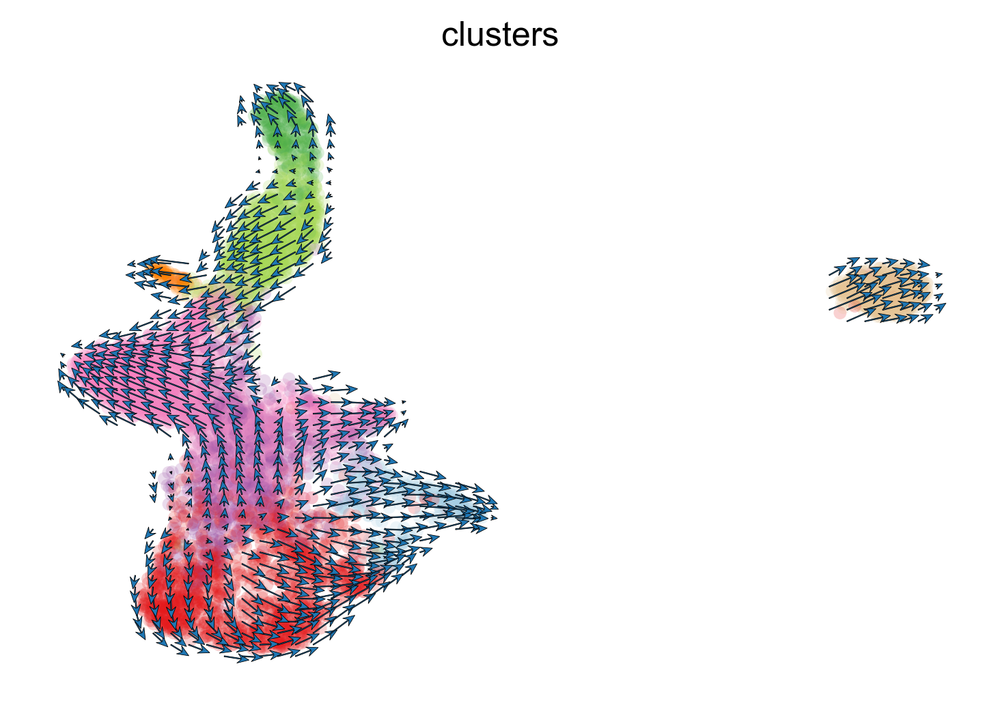

In [12]:
# Create a velocity plot 
scv.pl.velocity_embedding_grid(
    adata,
    basis="umap",
    arrow_length=4, # Change the arrow length
    #alpha=0.1,
    arrow_size=2, # Change the arrow size
    arrow_color="tab:blue", # Change the arrow color
    dpi=150,
)

Cell Continuity refers to a biological principle that a cell will come from a already exsiting cell. For deepvelo this would predict how well the model is able to predict the velocity of the cell based upon the velocity of the neighboring cells.

In [13]:
# Create the continuity confidence
continuity_confidence(adata, trainer)

added 'continuity_mse' (adata.layers)
added 'continuity_relative_error' (adata.layers)
added 'cell_continuity' (adata.obs)
added 'gene_continuity' (adata.var)
added 'gene_corr' (adata.var)
continuity threshold: 0.0
added 'continuous_gene' (adata.var)
correlation threshold: 0.0
added 'correlated_gene' (adata.var)


Plot the graphs for the cell continuity mse. Which this is the opposite of the continuity confidence as this would be looking for the error with the prediction.

Text(0.5, 0, 'log1p gene continuity mse')

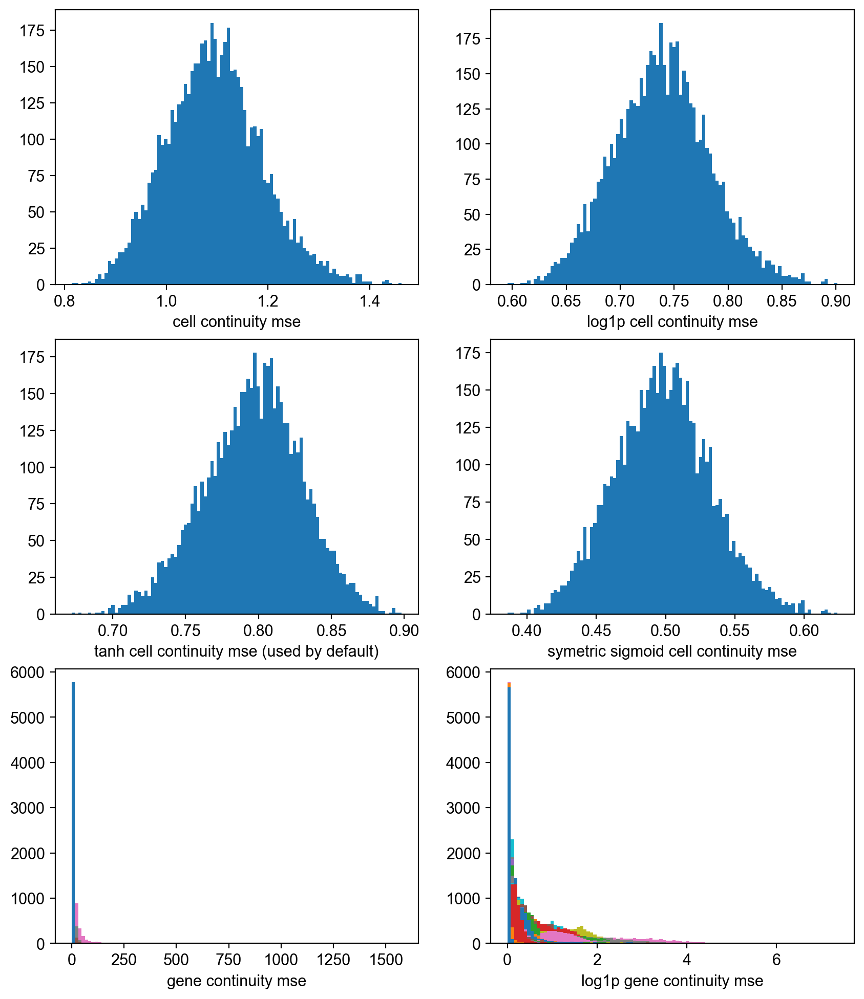

In [14]:
# show histogram of cell continuity mse
cell_continuity_mse = adata.layers["continuity_relative_error"].mean(axis=1) / (
        adata.layers["Ms"].mean(axis=1) + 1e-6
    )
from matplotlib import pyplot as plt
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(10, 12))
axes[0,0].hist(cell_continuity_mse, bins=100, histtype="stepfilled")
axes[0,0].set_xlabel("cell continuity mse")
axes[0,1].hist(np.log(1+cell_continuity_mse), bins=100, histtype="stepfilled")
axes[0,1].set_xlabel("log1p cell continuity mse")
axes[1,0].hist(np.tanh(cell_continuity_mse), bins=100, histtype="stepfilled")
axes[1,0].set_xlabel("tanh cell continuity mse (used by default)")
axes[1,1].hist(2/(1+np.exp(-cell_continuity_mse)) - 1, bins=100, histtype="stepfilled")
axes[1,1].set_xlabel("symetric sigmoid cell continuity mse")
axes[2,0].hist(trainer.confidence["mse"], bins=100, histtype="stepfilled")
axes[2,0].set_xlabel("gene continuity mse")
axes[2,1].hist(np.log(1+trainer.confidence["mse"]), bins=100, histtype="stepfilled")
axes[2,1].set_xlabel("log1p gene continuity mse")

The histograms shows that overall the data, the mse for some of the cell continuity are relatively high, even though they are evenly distributed. The x axis shows that its much higher compared to the article version.

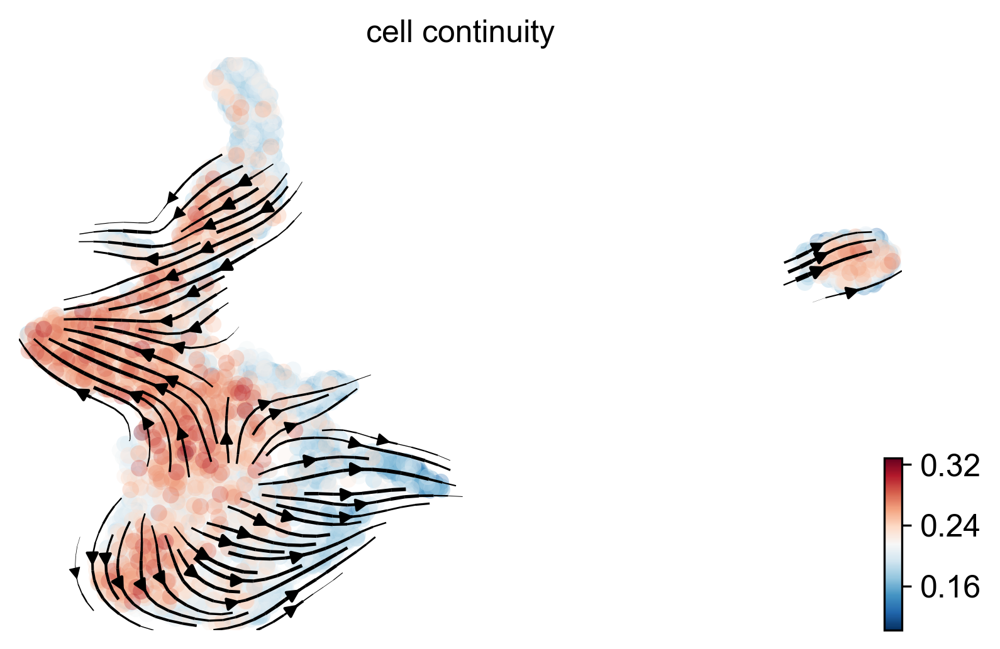

In [15]:
# velocity plot
scv.pl.velocity_embedding_stream(
    adata,
    basis="umap",
    color="cell_continuity",
    # color_map="heat",
    legend_fontsize=6,
    # perc=[2, 98],
    dpi=150            # increase dpi for higher resolution
)

Kinetic Rates

This refers to how quickly the RNA is able to move through the stages of RNA production and removal inside a cell.

α: transcription rate, how quickly new unspliced RNA is produced from DNA

β: splicing rate, how quickly unspliced RNA is converted into mature, spliced RNA.

γ: degradation rate, how quickly mature spliced RNA is broken down.



In [16]:
# Get the kinetic rates 
# get kinetic_rates
if "cell_specific_alpha" in adata.layers:
    all_rates = np.concatenate(
        [
            adata.layers["cell_specific_beta"],
            adata.layers["cell_specific_gamma"],
            adata.layers["cell_specific_alpha"],
        ],
        axis=1,
    )
    gene_wise_rates = np.concatenate(
        [
            adata.layers["cell_specific_beta"],
            adata.layers["cell_specific_gamma"],
            adata.layers["cell_specific_alpha"],
        ],
        axis=0,
    ).T
else:
    all_rates = np.concatenate(
        [
            adata.layers["cell_specific_beta"],
            adata.layers["cell_specific_gamma"],
        ],
        axis=1,
    )
    gene_wise_rates = np.concatenate(
        [
            adata.layers["cell_specific_beta"],
            adata.layers["cell_specific_gamma"],
        ],
        axis=0,
    ).T

# pca and umap of all rates
rates_pca = PCA(n_components=30, random_state=SEED).fit_transform(all_rates)
adata.obsm["X_rates_pca"] = rates_pca

rates_umap = UMAP(
    n_neighbors=60,
    min_dist=0.6,
    spread=0.9,
    random_state=SEED,
).fit_transform(rates_pca)
adata.obsm["X_rates_umap"] = rates_umap

# pca and umap of gene-wise rates
rates_pca_gene_wise = PCA(n_components=30, random_state=SEED).fit_transform(
    adata.layers["Ms"].T
)
adata.varm["rates_pca"] = rates_pca_gene_wise

rates_umap_gene_wise = UMAP(
    n_neighbors=60,
    min_dist=0.6,
    spread=0.9,
    random_state=SEED,
).fit_transform(rates_pca_gene_wise)
adata.varm["rates_umap"] = rates_umap_gene_wise

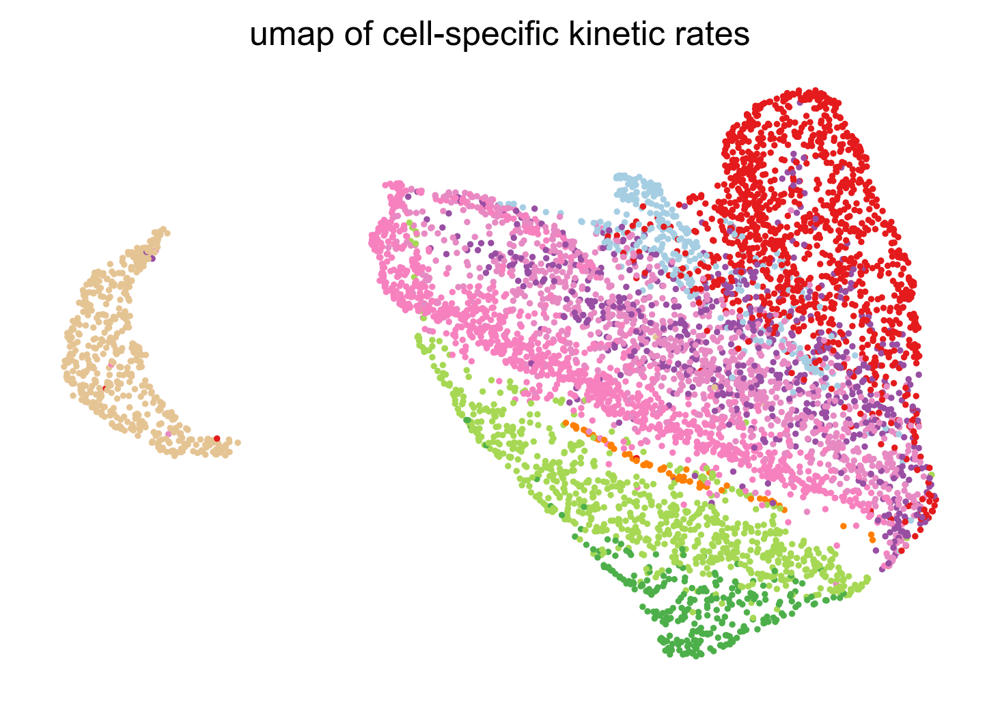

In [20]:
# Plot the kinetic rate umap 
scv.pl.scatter(
    adata,
    basis="rates_umap",
    #omit_velocity_fit=True,
    add_outline="Granule mature, Granule immature, Neuroblast",
    outline_width=(0.15, 0.3),
    title="umap of cell-specific kinetic rates",
    legend_loc="none",
    dpi=150,
)

I dont get this graph to be honest.

c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\matplotlib\fontconfig_pattern.py:127: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  self._parser.parseString(pattern)
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\matplotlib\fontconfig_pattern.py:134: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  self._parser.resetCache()
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\matplotlib\_mathtext.py:2022: PyparsingDeprecationWarning: 'setName' deprecated - use 'set_name'
  val.setName(key)
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\matplotlib\_mathtext.py:2033: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space         <<= oneOf(list(self._space_widths))
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\matplotlib\_mathtext.py:1878: PyparsingDeprecationWarning: 'setParseAction' deprecated - use 'set_parse_action'
  empty.setParseAction(rais

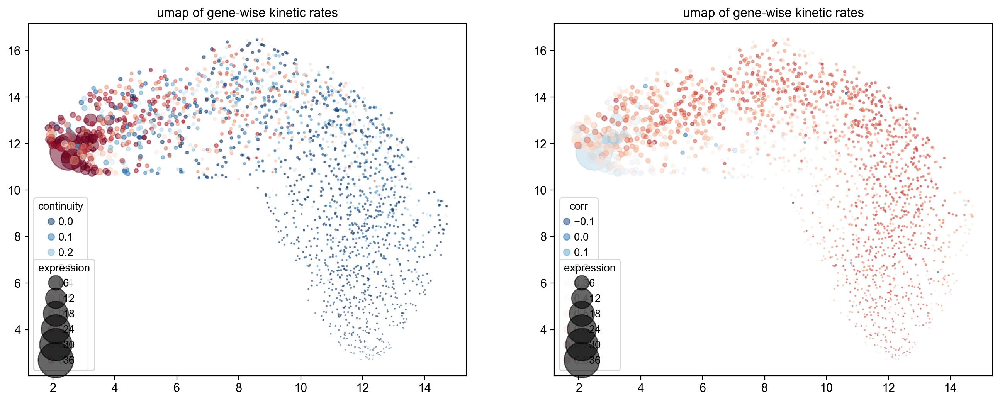

In [21]:
# plot rates_umap_gene_wise
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
visual_size = 30
scatter_plot = axes[0].scatter(
    rates_umap_gene_wise[:, 0],
    rates_umap_gene_wise[:, 1],
    c=adata.var["gene_continuity"],
    s=(adata.layers["Ms"].mean(axis=0) * visual_size).tolist(),
    alpha=0.5,
)
# color bar lim to 2%, 98% of continuity
continuity_lim = np.percentile(adata.var["gene_continuity"], [2, 98])
scatter_plot.set_clim(continuity_lim)
axes[0].set_title("umap of gene-wise kinetic rates")
axes[0].add_artist(
    axes[0].legend(
        *scatter_plot.legend_elements(),
        loc="lower left",
        title="continuity",
        title_fontsize="small",
        fontsize="small",
    )
)
axes[0].legend(
    *scatter_plot.legend_elements(prop="sizes", alpha=0.6, func=lambda s: s / visual_size, num=7),
    loc="best",
    title="expression",
    title_fontsize="small",
    fontsize="small",
)
scatter_plot = axes[1].scatter(
    rates_umap_gene_wise[:, 0],
    rates_umap_gene_wise[:, 1],
    c=adata.var["gene_corr"],
    s=(adata.layers["Ms"].mean(axis=0) * visual_size).tolist(),
    alpha=0.5,
)
axes[1].set_title("umap of gene-wise kinetic rates")
axes[1].add_artist(
    axes[1].legend(
        *scatter_plot.legend_elements(num=7),
        loc="lower left",
        title="corr",
        title_fontsize="small",
        fontsize="small",
    )
)
axes[1].legend(
    *scatter_plot.legend_elements(prop="sizes", alpha=0.6, func=lambda s: s / visual_size, num=7),
    loc="best",
    title="expression",
    title_fontsize="small",
    fontsize="small",
)

This seems to show that those genes that have a higher continuity and having a higher expression, also seem to have low correlation, hard to interpret the graph.

In the article they used these two genes "tmsb10", "ppp3ca", which were not present in my dataset, so I had to choose new ones.

In [ ]:
# These were the original genes
genes = ["tmsb10", "ppp3ca"]

for gene in genes:
    print(gene, gene in adata.var_names)

tmsb10 False
ppp3ca False


In [ ]:
# Find genes to use
print(adata.var_names[:50].tolist())

['CCNL2', 'NADK', 'CEP104', 'RERE', 'SLC2A5', 'CLSTN1', 'TMCO4', 'LUZP1', 'RUNX3', 'SYF2', 'RSRP1', 'GPATCH3', 'WASF2', 'AHDC1', 'IFI6', 'LAPTM5', 'BSDC1', 'SYNC', 'SNIP1', 'MTF1', 'SCMH1', 'HIVEP3', 'SVBP', 'GPBP1L1', 'EFCAB14', 'ECHDC2', 'PLPP3', 'MYSM1', 'JAK1', 'SLC35D1', 'ANKRD13C', 'NEGR1', 'CRYZ', 'RP11-475O6.1', 'CTBS', 'BCL10', 'COL24A1', 'ODF2L', 'KYAT3', 'GBP2', 'TMED5', 'DNTTIP2', 'DPYD', 'DBT', 'VAV3', 'SLC25A24', 'WDR47', 'TAF13', 'ST7L', 'RSBN1']


In [ ]:
# Look for the top correlated genes.
top_corr_genes = (
    adata.var
    .sort_values("gene_corr", ascending=False)
    [["gene_corr", "gene_continuity"]]
    .head(20)
)

top_corr_genes

,gene_corr,gene_continuity
index,,
MACROD2,0.871002,0.000000e+00
RASSF5,0.797796,2.606370e-01
LRRC7,0.794839,2.523184e-03
SERINC5,0.794307,0.000000e+00
COPZ1,0.790531,5.759197e-01
TRIB2,0.789486,5.462655e-01
XKR6,0.785921,0.000000e+00
LAX1,0.782216,4.768372e-07
SFR1,0.781770,4.882463e-01


Chose the genes RASSf5 and LRRC7 since they have relatively high correlation and high continuity.

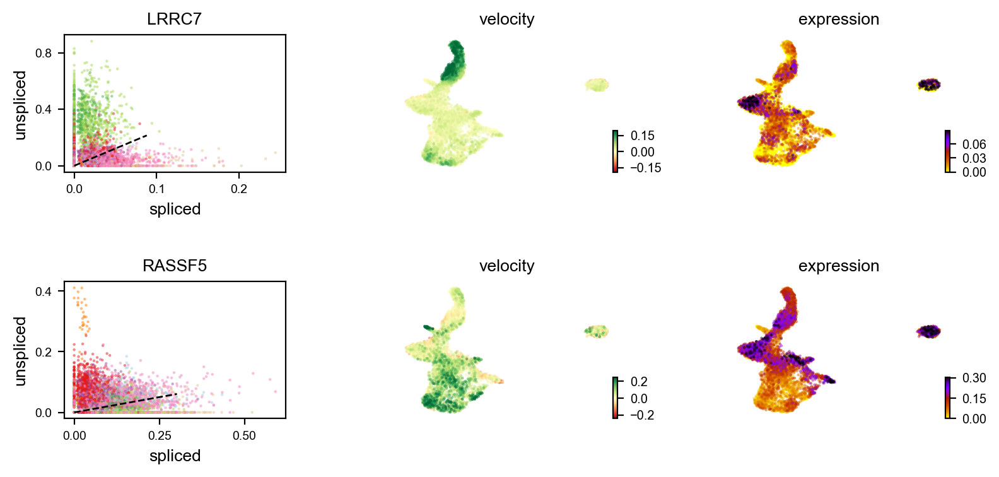

        gene_corr  gene_continuity
index                             
LRRC7    0.794834         0.002520
RASSF5   0.797792         0.260679


<Figure size 600x400 with 0 Axes>

In [22]:
# plot genes
scv.pl.velocity(
    adata,
    var_names=["LRRC7", "RASSF5"],
    basis="umap",
)
plt.tight_layout()
print(adata.var.loc[["LRRC7", "RASSF5"], ["gene_corr", "gene_continuity"]])

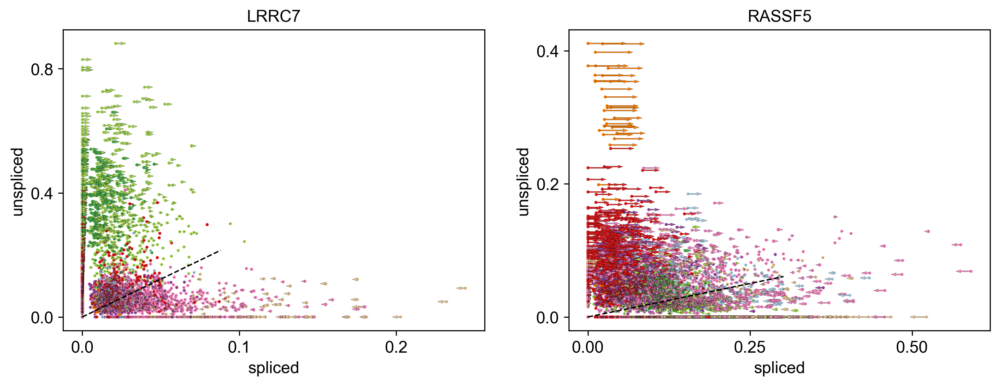

In [23]:

if "velocity_unspliced" not in adata.layers:
    adata.layers["velocity_unspliced"] = np.zeros_like(adata.layers["velocity"])
scatter(
    adata,
    basis=["LRRC7", "RASSF5"],
    add_quiver=True,
    dpi=150,
    legend_loc_lines="none",
)

# can have a figure showing the difference distribution of velocity vector length 
# and directions across celltypes, to show that we do have very clear power to 
# learn cell-specific patterns clearly distinguishing celltypes

In [ ]:
adata.var["gene_corr"].describe()

count    2000.000000
mean        0.578944
std         0.126120
min        -0.136624
25%         0.496657
50%         0.611247
75%         0.676137
max         0.871009
Name: gene_corr, dtype: float64

In [25]:
adata.var["gene_continuity"].describe()

count    2000.000000
mean        0.191140
std         0.225875
min         0.000000
25%         0.000843
50%         0.079634
75%         0.348861
max         0.909527
Name: gene_continuity, dtype: float64

Text(0.5, 0.98, 'least ranked genes by gene_corr')

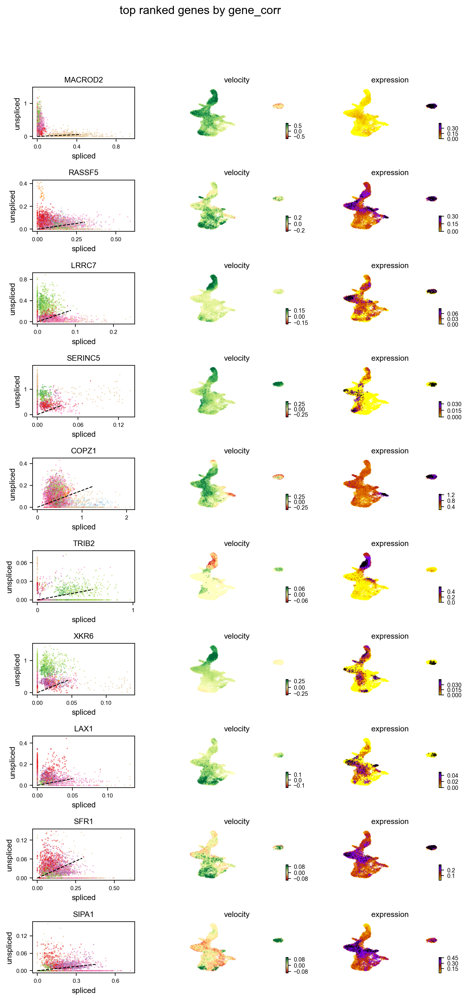

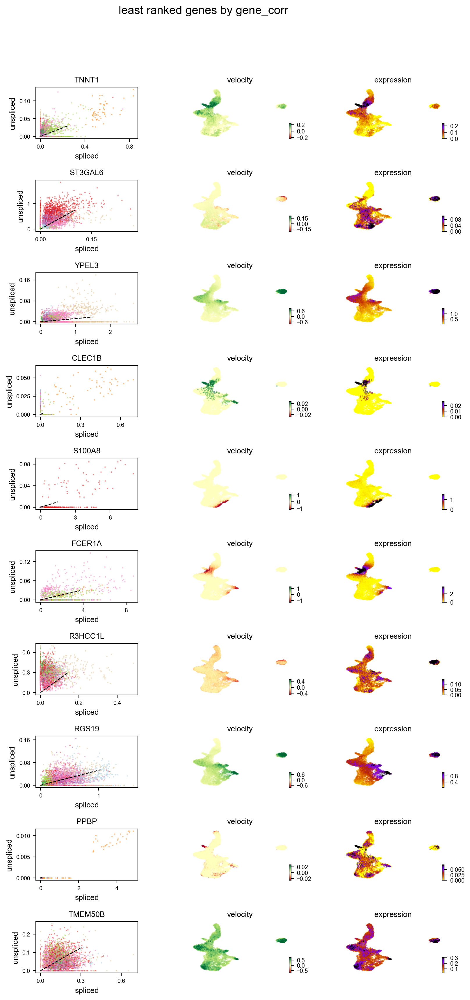

In [26]:
num_show_genes = 10
top_ranked_genes_corr = adata.var.sort_values("gene_corr", ascending=False).index[:num_show_genes]
least_ranked_genes_corr = adata.var.sort_values("gene_corr", ascending=False).index[-num_show_genes:]

ax = scv.pl.velocity(
    adata,
    var_names=top_ranked_genes_corr,
    basis="umap",
    show=False,
)
ax.get_figure().suptitle("top ranked genes by gene_corr")

ax = scv.pl.velocity(
    adata,
    var_names=least_ranked_genes_corr,
    basis="umap",
    show=False,
)
ax.get_figure().suptitle("least ranked genes by gene_corr")

Text(0.5, 0.98, 'least ranked genes by gene_continuity')

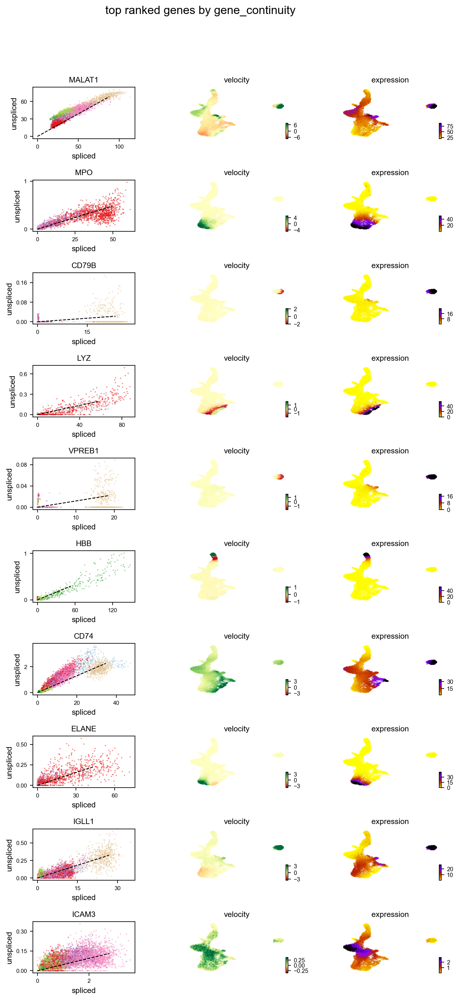

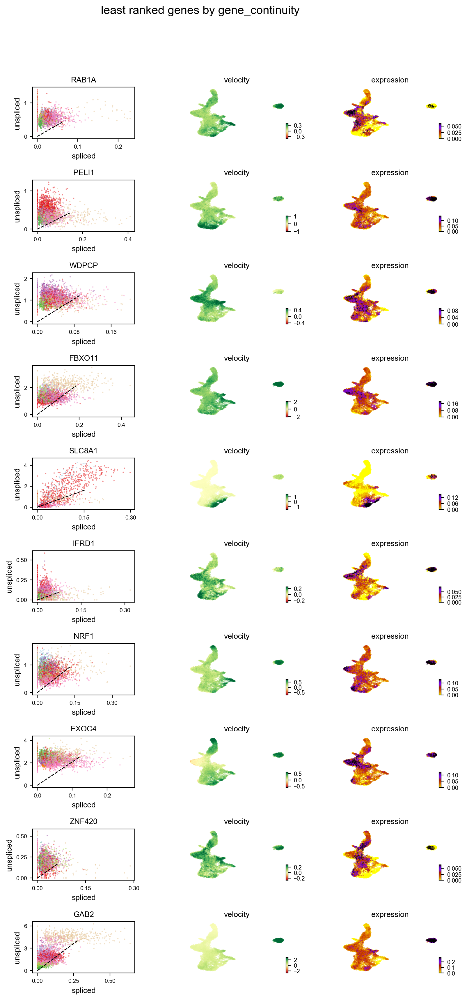

In [ ]:
top_ranked_genes_continuity = adata.var.sort_values("gene_continuity", ascending=False).index[:num_show_genes]
least_ranked_genes_continuity = adata.var.sort_values("gene_continuity", ascending=False).index[-num_show_genes:]

ax = scv.pl.velocity(
    adata,
    var_names=top_ranked_genes_continuity,
    basis="umap",
    show=False,
)
ax.get_figure().suptitle("top ranked genes by gene_continuity")

ax = scv.pl.velocity(
    adata,
    var_names=least_ranked_genes_continuity,
    basis="umap",
    show=False,
)
ax.get_figure().suptitle("least ranked genes by gene_continuity")

In [28]:
adata

AnnData object with n_obs × n_vars = 5780 × 2000
    obs: 'clusters', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'cell_continuity'
    var: 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'velocity_gamma', 'velocity_r2', 'velocity_genes', 'gene_continuity', 'gene_corr', 'continuous_gene', 'correlated_gene'
    uns: 'clusters_colors', 'pca', 'neighbors', 'velocity_params', 'umap', 'velocity_graph', 'velocity_graph_neg'
    obsm: 'X_tsne', 'X_pca', 'X_umap', 'velocity_umap', 'X_rates_pca', 'X_rates_umap'
    varm: 'PCs', 'rates_pca', 'rates_umap'
    layers: 'spliced', 'unspliced', 'Ms', 'Mu', 'velocity', 'variance_velocity', 'cell_specific_beta', 'cell_specific_gamma', 'continuity_mse', 'continuity_relative_error', 'velocity_unspliced'
    obsp: 'distances', 'connectivities'

In [29]:
scv.tl.velocity_pseudotime(adata)

computing terminal states
    identified 3 regions of root cells and 2 regions of end points .
    finished (0:00:00) --> added
    'root_cells', root cells of Markov diffusion process (adata.obs)
    'end_points', end points of Markov diffusion process (adata.obs)


In [30]:
# driver genes
from scipy.stats import pearsonr

time_corr = []
time_corr_pval = []
for gene in adata.var_names:
    tcorr, pval = pearsonr(adata.obs["velocity_pseudotime"], adata[:, gene].layers["Ms"].mean(axis=1))
    time_corr.append(tcorr)
    time_corr_pval.append(pval)

adata.var["time_corr"] = time_corr
adata.var["time_corr_abs"] = np.abs(time_corr)
adata.var["time_corr_pval"] = time_corr_pval

c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\matplotlib\_mathtext.py:2237: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\matplotlib\_mathtext.py:2300: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1])
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\matplotlib\_mathtext.py:2245: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  self._expression.resetCache()


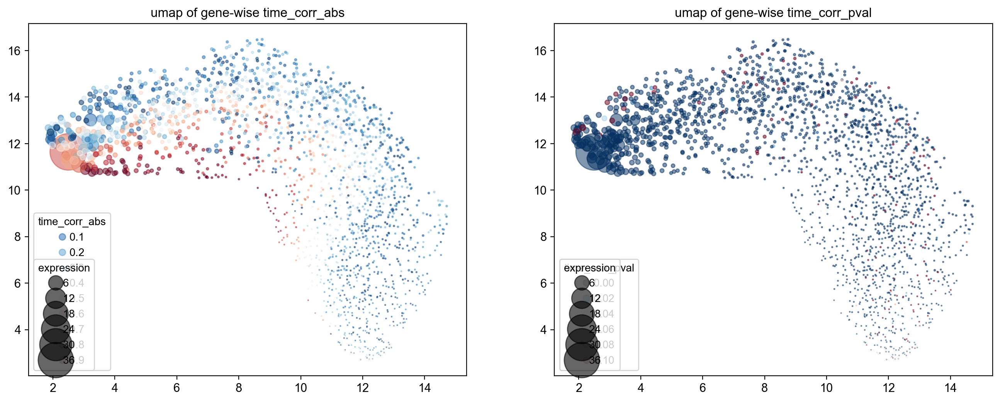

In [31]:
# plot rates_umap_gene_wise
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
visual_size = 30
scatter_plot = axes[0].scatter(
    rates_umap_gene_wise[:, 0],
    rates_umap_gene_wise[:, 1],
    c=adata.var["time_corr_abs"],
    s=(adata.layers["Ms"].mean(axis=0) * visual_size).tolist(),
    alpha=0.5,
)
# color bar lim to 2%, 98% of continuity
continuity_lim = np.percentile(adata.var["time_corr_abs"], [2, 98])
scatter_plot.set_clim(continuity_lim)
axes[0].set_title("umap of gene-wise time_corr_abs")
axes[0].add_artist(
    axes[0].legend(
        *scatter_plot.legend_elements(),
        loc="lower left",
        title="time_corr_abs",
        title_fontsize="small",
        fontsize="small",
    )
)
axes[0].legend(
    *scatter_plot.legend_elements(prop="sizes", alpha=0.6, func=lambda s: s / visual_size, num=7),
    loc="best",
    title="expression",
    title_fontsize="small",
    fontsize="small",
)
scatter_plot = axes[1].scatter(
    rates_umap_gene_wise[:, 0],
    rates_umap_gene_wise[:, 1],
    c=np.clip(adata.var["time_corr_pval"], 0, 0.1),
    s=(adata.layers["Ms"].mean(axis=0) * visual_size).tolist(),
    alpha=0.5,
)
axes[1].set_title("umap of gene-wise time_corr_pval")
axes[1].add_artist(
    axes[1].legend(
        *scatter_plot.legend_elements(num=7),
        loc="lower left",
        title="time_corr_pval",
        title_fontsize="small",
        fontsize="small",
    )
)
axes[1].legend(
    *scatter_plot.legend_elements(prop="sizes", alpha=0.6, func=lambda s: s / visual_size, num=7),
    loc="best",
    title="expression",
    title_fontsize="small",
    fontsize="small",
)

,time_corr,time_corr_abs,time_corr_pval
index,,,
VPREB1,0.936841,0.936841,0.0
CD79B,0.936731,0.936731,0.0
VPREB3,0.935346,0.935346,0.0
LAPTM5,0.930941,0.930941,0.0
AKAP12,0.927468,0.927468,0.0
LEF1,0.923433,0.923433,0.0
ARPP21,0.922366,0.922366,0.0
CD9,0.918114,0.918114,0.0
LINC01013,0.913754,0.913754,0.0


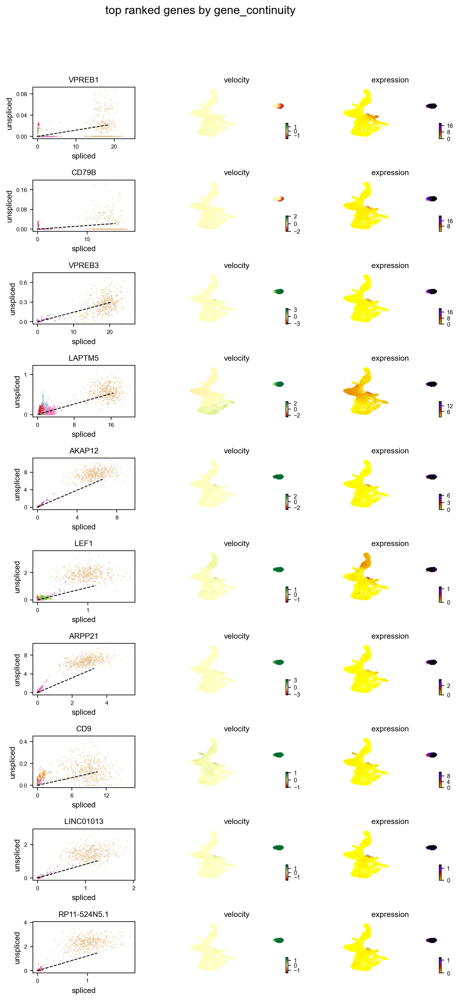

In [32]:
top_ranked_genes_continuity = adata.var.sort_values("time_corr_abs", ascending=False).index[:num_show_genes]
least_ranked_genes_continuity = adata.var.sort_values("time_corr_abs", ascending=False).index[-num_show_genes:]

ax = scv.pl.velocity(
    adata,
    var_names=top_ranked_genes_continuity,
    basis="umap",
    show=False,
)
ax.get_figure().suptitle("top ranked genes by gene_continuity")

adata.var.loc[top_ranked_genes_continuity, ["time_corr", "time_corr_abs", "time_corr_pval"]]

In [33]:
# pick lineages by selecting celltypes or louvain clusters on velocity graph
# save adata for next steps
deepvelo_adata = adata.copy()

In [1]:
deepvelo_adata.obs.columns

NameError: name 'deepvelo_adata' is not defined

scVelo(dynamical)

In [34]:
adata = ann.read_h5ad(r"C:\Users\joshu\Desktop\RNA_Velocity_R\DeepVelo\Figure_2_Follow\human_cd34_bone_marrow.h5ad")
scv.pp.filter_and_normalize(adata, min_shared_counts=20, n_top_genes=2000)
scv.pp.moments(adata, n_neighbors=30, n_pcs=30)

Filtered out 7837 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.
Extracted 2000 highly variable genes.
Logarithmized X.
computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


In [35]:
scv.tl.recover_dynamics(adata, n_jobs=4)
scv.tl.velocity(adata, mode="dynamical")

recovering dynamics (using 4/8 cores)


  0%|          | 0/558 [00:00<?, ?gene/s]

    finished (0:01:49) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:02) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)


In [36]:
scv.tl.velocity_graph(adata, n_jobs=4)

computing velocity graph (using 4/8 cores)


  0%|          | 0/5780 [00:00<?, ?cells/s]

    finished (0:00:04) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


In [37]:
# Create a umap
sc.pp.neighbors(
    adata,
    n_neighbors=30,
    n_pcs=30
)

sc.tl.umap(adata)

In [38]:
# Confirm the umap was created
print("X_umap" in adata.obsm)
print(adata.obsm["X_umap"].shape)

True
(5780, 2)


computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


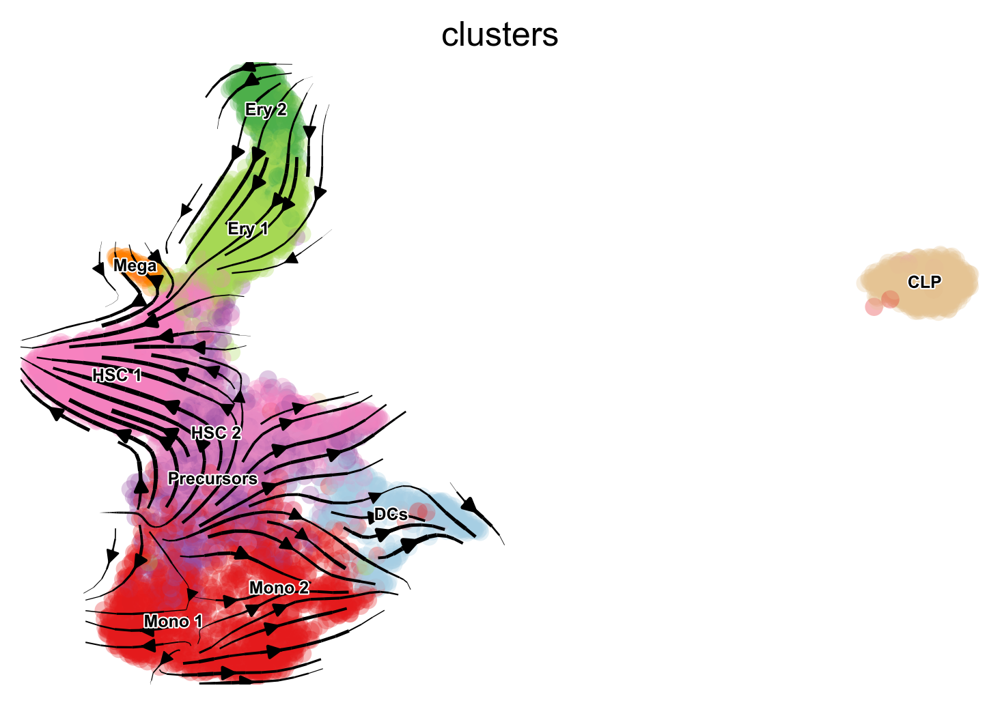

In [39]:
# velocity plot
scv.pl.velocity_embedding_stream(
    adata,
    basis="umap",
    color="clusters",
    legend_fontsize=6,
    dpi=150            # increase dpi for higher resolution
)

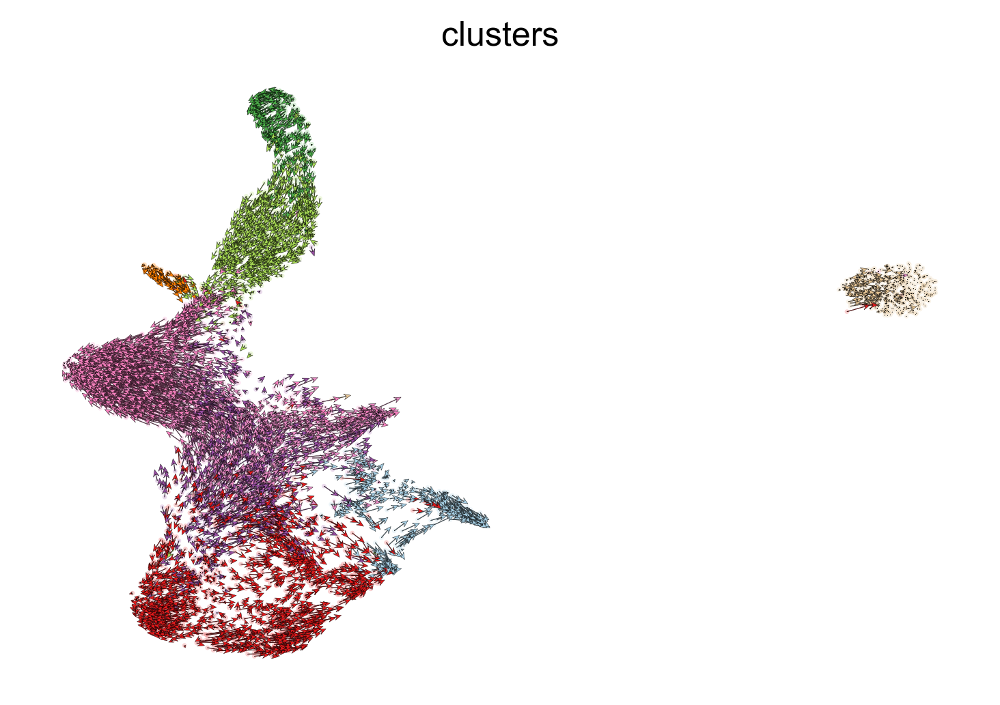

In [40]:
scv.pl.velocity_embedding(
    adata,
    basis="umap",
    arrow_length=6,
    arrow_size=1.2,
    dpi=150,
)

c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\numpy\core\fromnumeric.py:57: DeprecationWarning: Passing `np.nan` to mean no clipping in np.clip has always been unreliable, and is now deprecated. In future, this will always return nan, like it already does when min or max are arrays that contain nan. To skip a bound, pass either None or an np.inf of an appropriate sign.
  return bound(*args, **kwds)
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\numpy\core\fromnumeric.py:57: DeprecationWarning: Passing `np.nan` to mean no clipping in np.clip has always been unreliable, and is now deprecated. In future, this will always return nan, like it already does when min or max are arrays that contain nan. To skip a bound, pass either None or an np.inf of an appropriate sign.
  return bound(*args, **kwds)


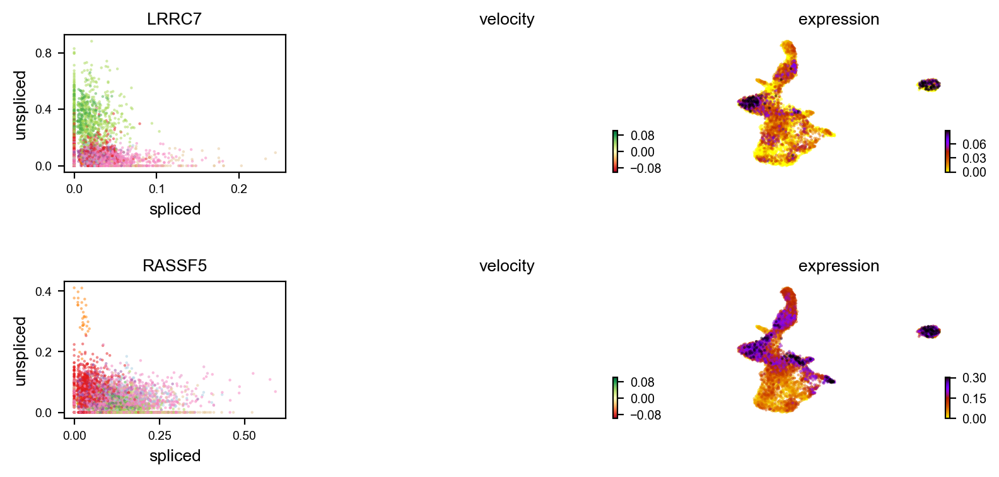

In [42]:
# plot genes
scv.pl.velocity(
    adata,
    var_names=["LRRC7", "RASSF5"],
    basis="umap",
)

Trajectory Inference

This refers to the process of estimating how the cells may progress from one biological state to another using single-cell data.

computing terminal states
    identified 3 regions of root cells and 1 region of end points .
    finished (0:00:00) --> added
    'root_cells', root cells of Markov diffusion process (adata.obs)
    'end_points', end points of Markov diffusion process (adata.obs)
running PAGA using priors: ['velocity_pseudotime']
    finished (0:00:00) --> added
    'paga/connectivities', connectivities adjacency (adata.uns)
    'paga/connectivities_tree', connectivities subtree (adata.uns)
    'paga/transitions_confidence', velocity transitions (adata.uns)


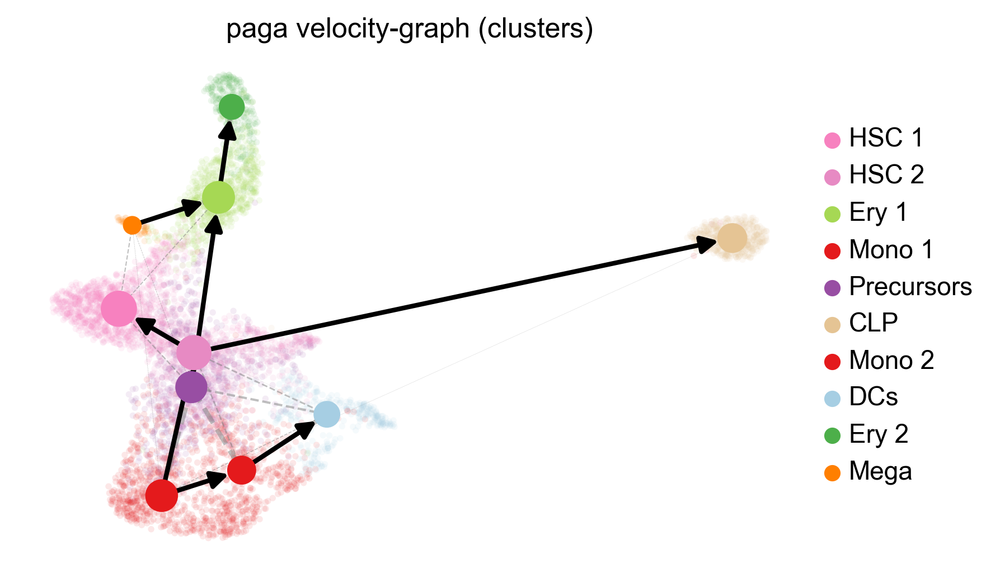

In [43]:
# trajectory inference
adata.uns['neighbors']['distances'] = adata.obsp['distances']
adata.uns['neighbors']['connectivities'] = adata.obsp['connectivities']
scv.tl.paga(adata, groups="clusters")
scv.pl.paga(
    adata,
    basis="umap",
    size=30,
    alpha=0.1,
    min_edge_width=2,
    node_size_scale=1,
    dpi=150,
)

In [44]:
dynamical_adata = adata.copy()

## Compare Direction Scores


Direction Scores measure whether the predicted RNA velocities point in the known biological direction of development. Which the deepvelo is able to calculate this by using the cosine similarity from the predicted velocity direction and the expression space direction from a cell in type A toward the neighboring cells in type B

In [45]:
print(deepvelo_adata.obs["clusters"].unique())

['Ery_1', 'HSC_1', 'Mono_1', 'Precursors', 'Mega', 'HSC_2', 'Mono_2', 'Ery_2', 'DCs', 'CLP']
Categories (10, object): ['HSC_1', 'HSC_2', 'Ery_1', 'Mono_1', ..., 'Mono_2', 'DCs', 'Ery_2', 'Mega']


In [46]:
distances = deepvelo_adata.obsp["distances"].tocsr()

n_neighbors = 30
neighbor_indices = np.full(
    (deepvelo_adata.n_obs, n_neighbors),
    -1,
    dtype=int
)

for i in range(deepvelo_adata.n_obs):
    start = distances.indptr[i]
    end = distances.indptr[i + 1]

    row_indices = distances.indices[start:end]
    row_distances = distances.data[start:end]

    order = np.argsort(row_distances)
    selected = row_indices[order][:n_neighbors]

    neighbor_indices[i, :len(selected)] = selected

deepvelo_adata.uns["neighbors"]["indices"] = neighbor_indices

In [47]:
cluster_edges = [
    ("HSC_1", "HSC_2"),
    ("HSC_2", "Precursors"),
    ("Precursors", "Ery_1"),
    ("Precursors", "Mono_1"),
    ("Precursors", "Mega"),
    ("Precursors", "CLP"),
]
cbcs, avg_cbc = cross_boundary_correctness(
    deepvelo_adata, "clusters", "velocity", cluster_edges, return_raw=False # x_emb="X_umap"
)
print(f"Average cross-boundary correctness of DeepVelo: {avg_cbc:.2f}")
cbcs

added 'direction_scores' (adata.uns)
added 'raw_direction_scores' (adata.uns)
Average cross-boundary correctness of DeepVelo: -0.30


{('HSC_1', 'HSC_2'): -0.4021205099147499,
 ('HSC_2', 'Precursors'): -0.26235399909603724,
 ('Precursors', 'Ery_1'): -0.32577596126060016,
 ('Precursors', 'Mono_1'): -0.0659690420701506,
 ('Precursors', 'Mega'): 0.3902893648969779,
 ('Precursors', 'CLP'): 0.8071279293929443}

In [48]:
distances = dynamical_adata.obsp["distances"].tocsr()

n_neighbors = 30
neighbor_indices = np.full(
    (dynamical_adata.n_obs, n_neighbors),
    -1,
    dtype=int
)

for i in range(dynamical_adata.n_obs):
    start = distances.indptr[i]
    end = distances.indptr[i + 1]

    row_indices = distances.indices[start:end]
    row_distances = distances.data[start:end]

    order = np.argsort(row_distances)
    selected = row_indices[order][:n_neighbors]

    neighbor_indices[i, :len(selected)] = selected

dynamical_adata.uns["neighbors"]["indices"] = neighbor_indices

In [49]:
cbcs, avg_cbc = cross_boundary_correctness(
    dynamical_adata, "clusters", "velocity", cluster_edges, return_raw=False # x_emb="X_umap"
)
print(f"Average cross-boundary correctness of Dynamical: {avg_cbc:.2f}")
cbcs

added 'direction_scores' (adata.uns)
added 'raw_direction_scores' (adata.uns)
Average cross-boundary correctness of Dynamical: -0.31


{('HSC_1', 'HSC_2'): -0.40102678574296924,
 ('HSC_2', 'Precursors'): -0.2771374679402267,
 ('Precursors', 'Ery_1'): 0.2871653538514728,
 ('Precursors', 'Mono_1'): -0.2646313320174176,
 ('Precursors', 'Mega'): 0.38183895667399476,
 ('Precursors', 'CLP'): 0.733132618399025}

Velocity Confidence

This measures how consistently a cells predicted RNA-Velocity vector agrees with the velocity vector of its neighboring cells.

--> added 'velocity_length' (adata.obs)
--> added 'velocity_confidence_cosine' (adata.obs)
--> added 'velocity_length' (adata.obs)
--> added 'velocity_confidence_cosine' (adata.obs)
DeepVelo mean score: 0.9256, std: 0.0239
Dynamical mean score: 0.8591, std: 0.0824


(<AxesSubplot:>, <AxesSubplot:ylabel='Overall consistency'>)

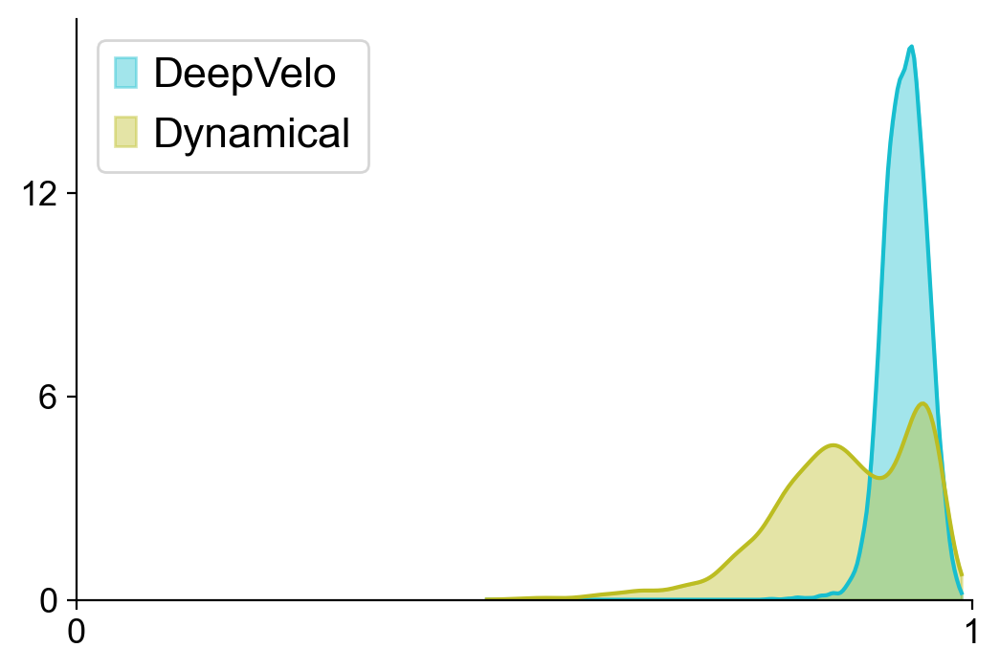

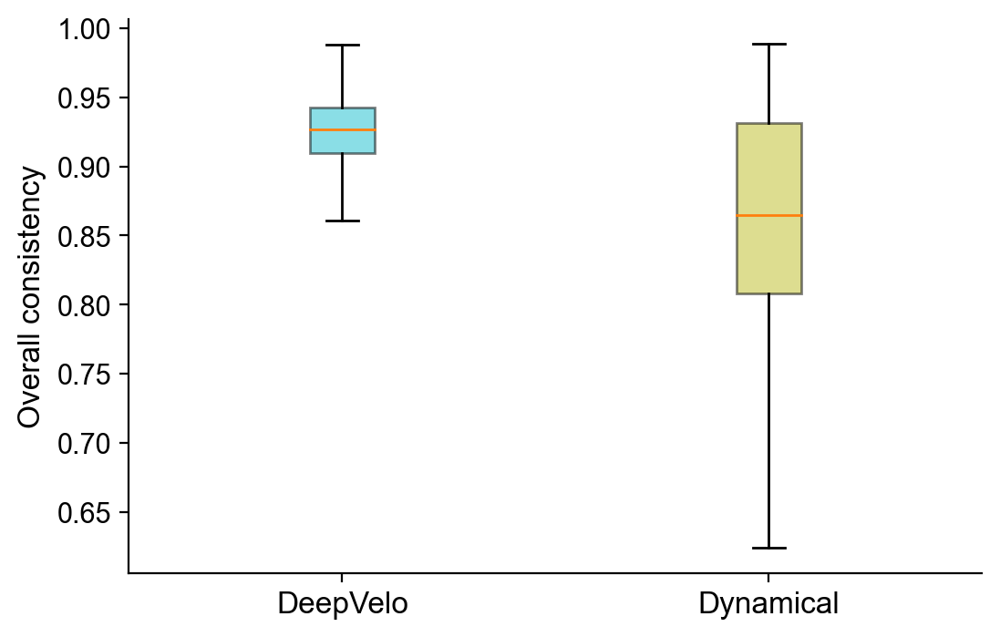

In [50]:
vkey = "velocity"
method = "cosine"
velocity_confidence(deepvelo_adata, vkey=vkey, method=method)
velocity_confidence(dynamical_adata, vkey=vkey, method=method)
compare_plot(deepvelo_adata, dynamical_adata, method=method)

In [51]:
# Mann-Whitney U Test test
stat, p = mannwhitneyu(
    deepvelo_adata.obs["velocity_confidence_cosine"].tolist(),
    dynamical_adata.obs["velocity_confidence_cosine"].tolist(),
)
print(f"Statistics={stat:.3f}, {p}")
# interpret
alpha = 0.05
if p > alpha:
    print("Same distribution (fail to reject H0)")
else:
    print("Different distribution (reject H0)")

Statistics=24787792.000, 0.0
Different distribution (reject H0)


Take Away:

The average velocity confidence is higher when using the tool deepvelo, compared to the tool scvelo dynamical. As the average velocity confidence is 0.92 compared to 0.86.

We are able to reject the null hypothesis meaning that they are statistically different.

Add the scope of looking within each cluster. For a deeper analysis on the velocity confidence.

--> added 'velocity_length' (adata.obs)
--> added 'velocity_confidence_cosine' (adata.obs)
--> added 'velocity_length' (adata.obs)
--> added 'velocity_confidence_cosine' (adata.obs)
DeepVelo mean score: 0.8109, std: 0.0648
Dynamical mean score: 0.6540, std: 0.1949


(<AxesSubplot:>, <AxesSubplot:ylabel='Overall consistency'>)

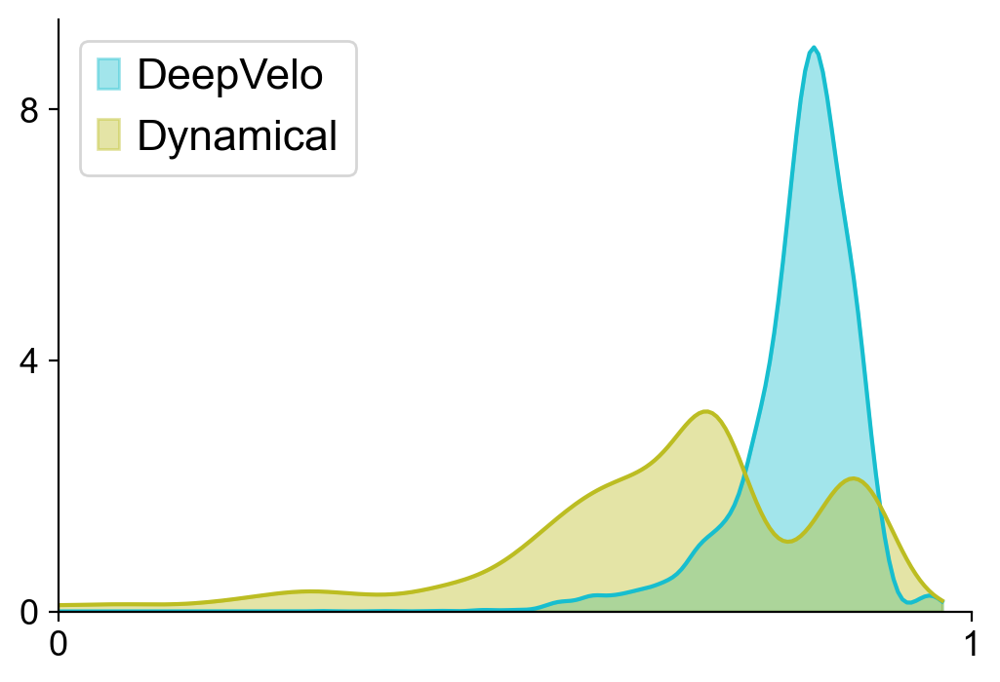

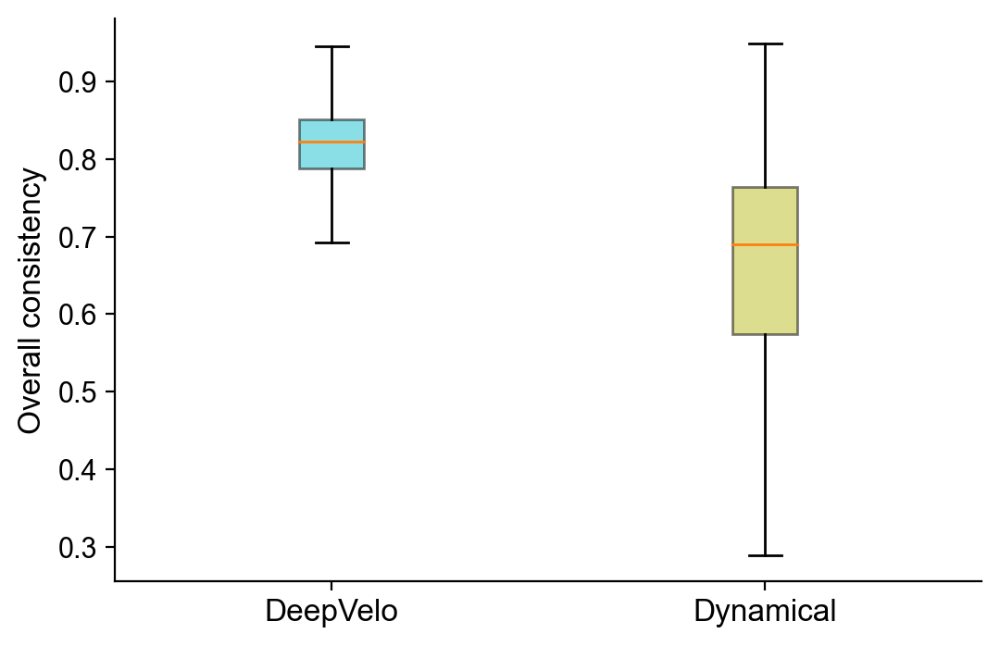

In [52]:
vkey = "velocity"
method = "cosine"
scope_key = "clusters"
# 3. cosine similarity, compute within Celltype
velocity_confidence(deepvelo_adata, vkey=vkey, method=method, scope_key=scope_key)
velocity_confidence(dynamical_adata, vkey=vkey, method=method, scope_key=scope_key)
compare_plot(deepvelo_adata, dynamical_adata, method=method)

In [53]:
# Mann-Whitney U Test test
stat, p = mannwhitneyu(
    deepvelo_adata.obs["velocity_confidence_cosine"].tolist(),
    dynamical_adata.obs["velocity_confidence_cosine"].tolist(),
)
print(f"Statistics={stat:.3f}, {p}")
# interpret
alpha = 0.05
if p > alpha:
    print("Same distribution (fail to reject H0)")
else:
    print("Different distribution (reject H0)")

Statistics=25837786.000, 0.0
Different distribution (reject H0)


Transition Matrix

The whole goal is to try to predict how much protein is being made.

### NOTES

Look into Cell Rank.

Try to use either this or that. 

Take away:

Looking at the clusters in the terms of the velocity confidecne we are able to see that this would further show that Deepvelo is better at predicting compared to the scvelo dynamically. 

In [2]:
scv.tl.velocity_graph(adata, vkey="velocity", sqrt_transform=True, approx=True, n_recurse_neighbors=1)

t_mat = scv.utils.get_transition_matrix(adata, vkey="velocity", self_transitions=False, backward=True)

NameError: name 'scv' is not defined